Crucial points to keep under, when the amount of members who need to include it in their tax return increases: [8937, 11643, 20489, 23025, 44742, 59618, 62568, 71541, 71842, 79490, 83423, 89427, 90934, 119235, 125135, 143684]
Changes in amount of people who need to tax: [1, 2, 3, 4, 6, 7, 8, 9, 10, 13, 14, 15, 16, 18, 20, 21]


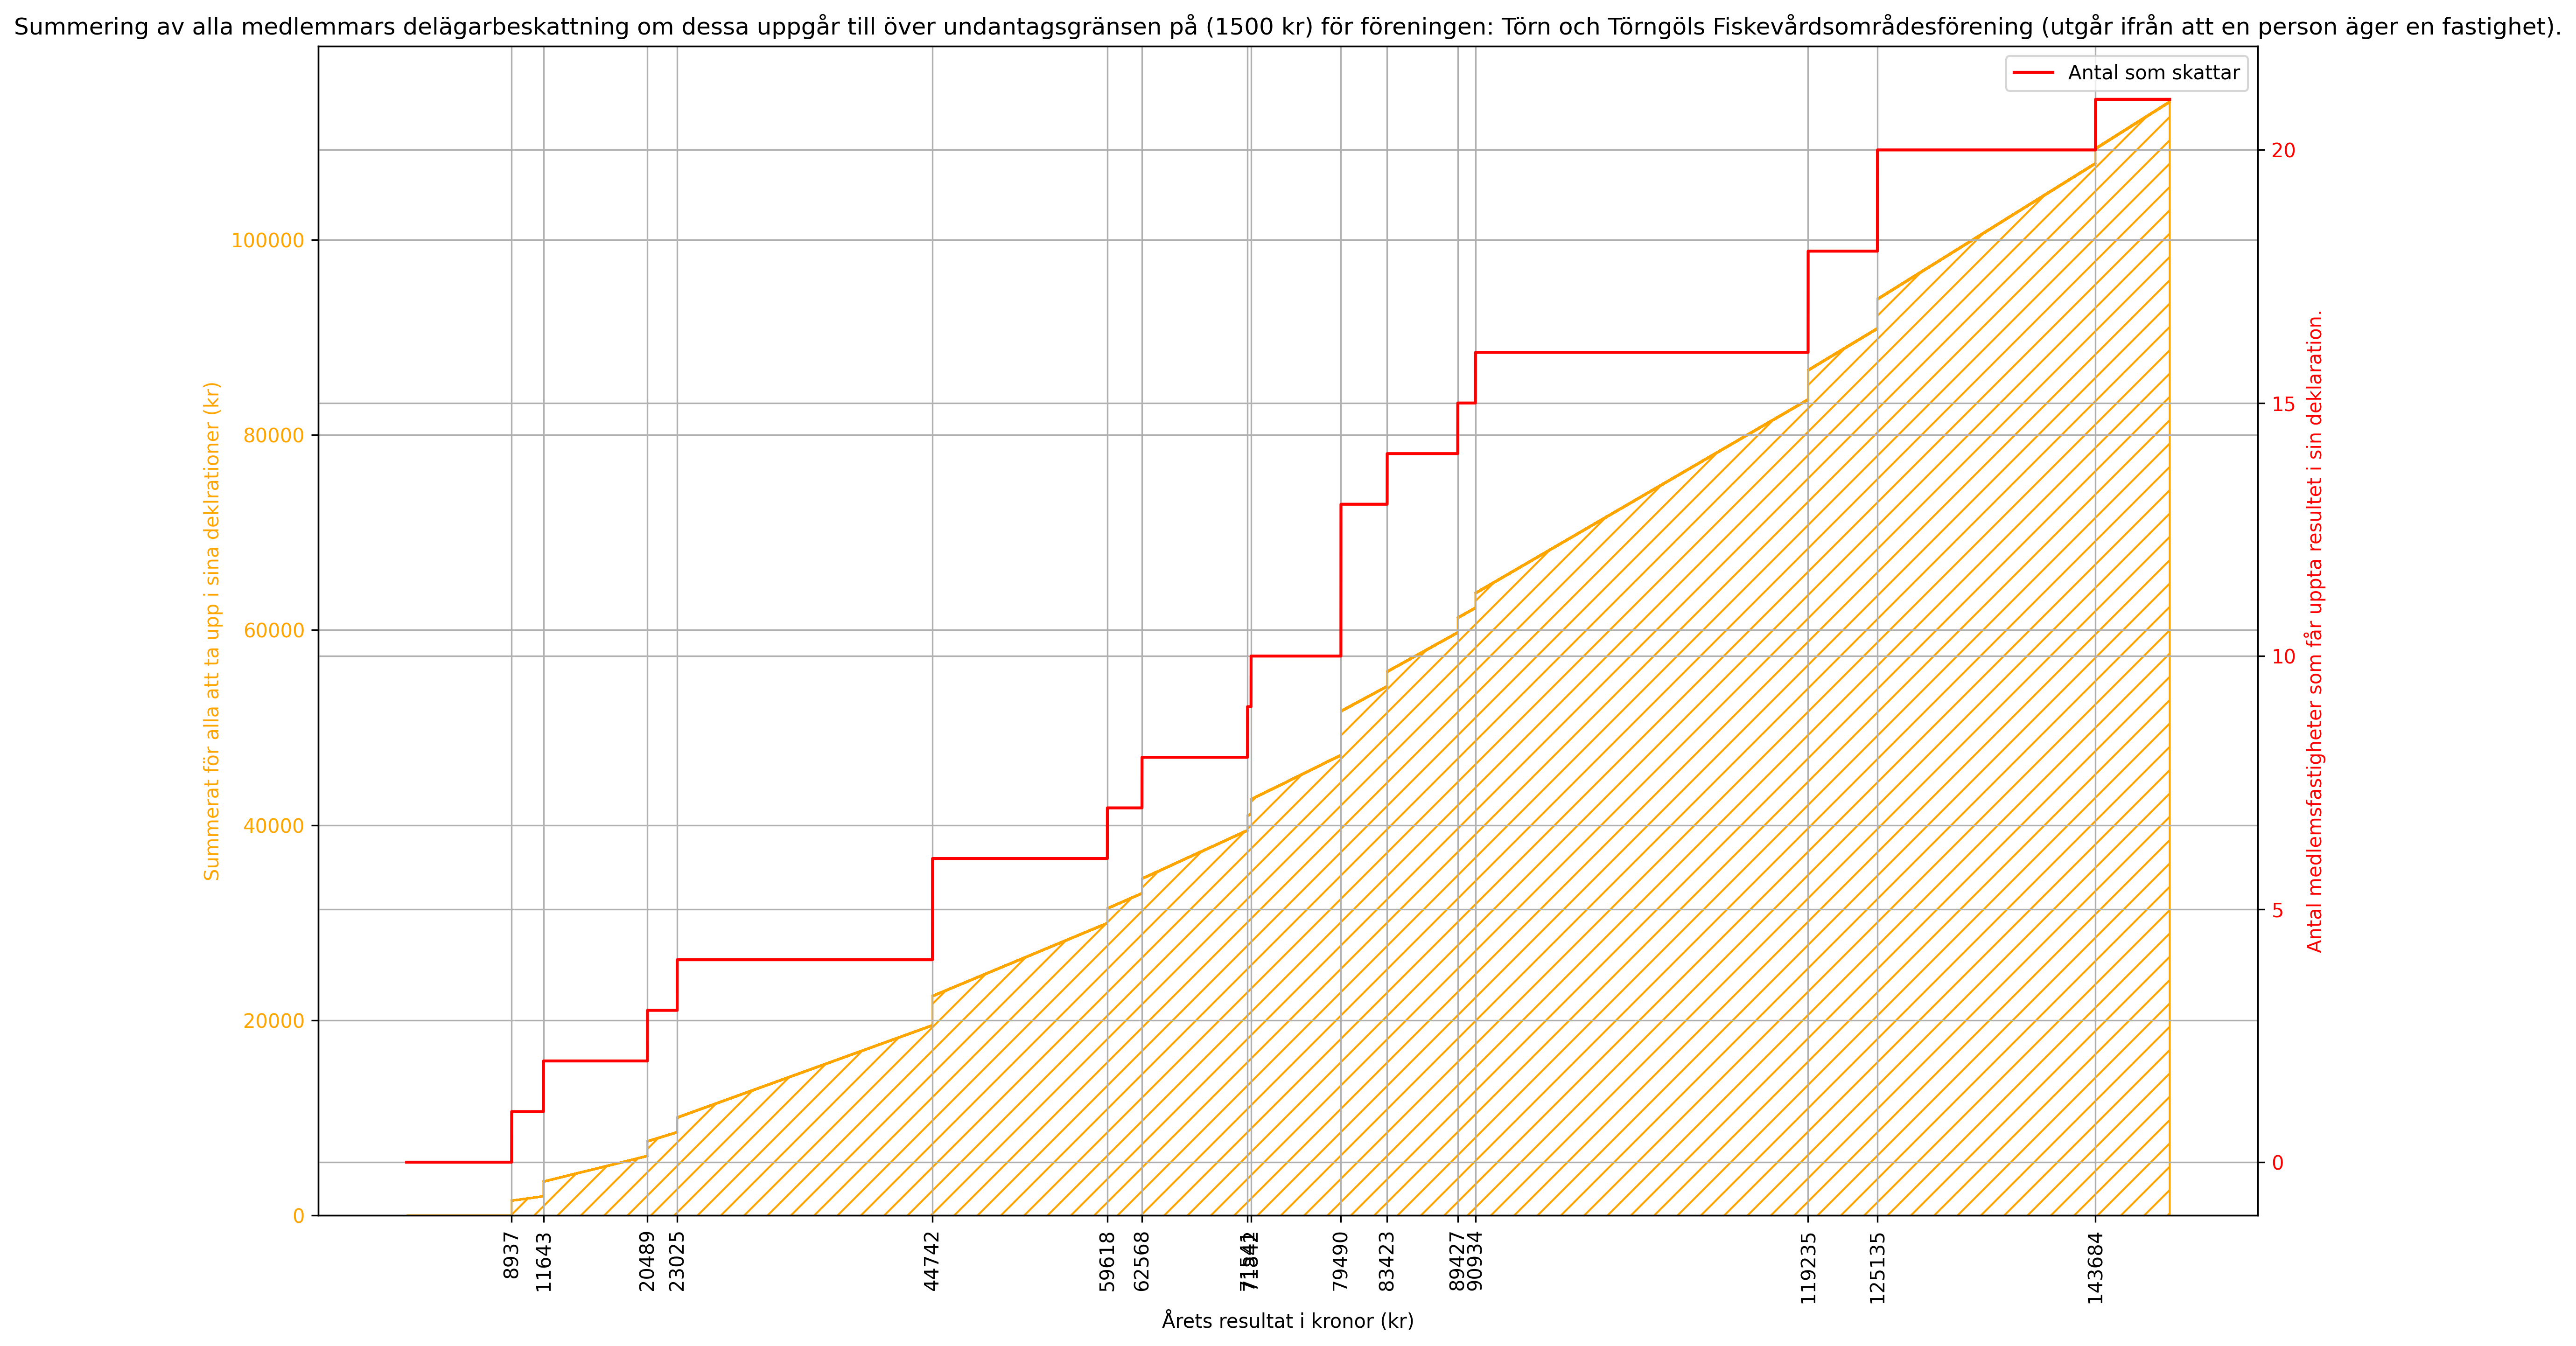

In [ ]:
import matplotlib.pyplot as plt
import csv

# CHANGE Input parameters if you need!
nameOfFVOF = "Törn och Törngöls Fiskevårdsområdesförening"
maxResult = 150000 # Sets the limit on how far to simulate result.
undantag = 1500 # Undantag ifrån Skatteverket.
fileNameOfTheShares = 'Beskattning.csv'

# Reads the csv file with the shares of the entire Fiskevårdsområdesförening.
def readCSV(filename):
    andelar = []
    with open(filename, newline='') as csvfile:
        shareReader = csv.reader(csvfile, delimiter=' ')
        for row in shareReader:
            andelar.append(row)
    return andelar

def simulate(andelar):
    # Simulation values/lists:
    totalDeclaredEveryone = []
    howManyDeclares = []
    tickListSharpIncreaseXAxis = []
    tickListSharpIncreaseCountYAxis = []
    currentSimulatedResultat = 0
    while maxResult > currentSimulatedResultat:
        sumOfAllFractionsToTax = 0
        howManyDeclaresOnSpecificResult = 0
        for propertiesFractions in andelar:
            fraction = float(propertiesFractions[0].replace(',', '.')) # replace comma with dot for decimal in python.
            taxForOneProperty = int(fraction * currentSimulatedResultat) # Antar att man får avrunda ner för skatteverket.

            if taxForOneProperty > undantag:
                howManyDeclaresOnSpecificResult += 1
                sumOfAllFractionsToTax += taxForOneProperty
        totalDeclaredEveryone.append(sumOfAllFractionsToTax)
        howManyDeclares.append(howManyDeclaresOnSpecificResult)

        # Checks if the amount who needs to tax is not the same as the last pass 
        # and adds it to be able to add ticks on the X-Axis on crucial breakpoints.
        if howManyDeclares[currentSimulatedResultat-1] != howManyDeclares[currentSimulatedResultat] and len(howManyDeclares) > 0:
            tickListSharpIncreaseXAxis.append(currentSimulatedResultat)
            tickListSharpIncreaseCountYAxis.append(howManyDeclaresOnSpecificResult)

        currentSimulatedResultat += 1 #Increments counter for while loop.
    return tickListSharpIncreaseXAxis, tickListSharpIncreaseCountYAxis,  totalDeclaredEveryone, howManyDeclares

tickListSharpIncreaseXAxis, tickListSharpIncreaseCountYAxis,  totalDeclaredEveryone, howManyDeclares = simulate(readCSV(fileNameOfTheShares))

# Initalizes two plots: 
fig, ax1 = plt.subplots()

# Stairs with the total sum of all the money to bring into your tax return:
ax1.set_xlabel("Årets resultat i kronor (kr)")
plt.grid() # Draws grid lines on x-axis.

# Sets the ticks steps to match the intresting "breakpoints" for when optimzing this years result.

print("Crucial points to keep under, when the amount of members who need to include it in their tax return increases: " + str(tickListSharpIncreaseXAxis))
print("Changes in amount of people who need to tax: " + str(tickListSharpIncreaseCountYAxis))

ax1.set_ylabel("Summerat för alla att ta upp i sina deklrationer (kr)", color="orange")
ax1.tick_params(axis='y', labelcolor="orange")

ax1.stairs(totalDeclaredEveryone, hatch="//", label='Totalt att skatta för medlemmar', color="orange")


# Second plot for the amount of people which is over the undantagstillstånd:
ax2 = ax1.twinx() # instantiate a second Axes that shares the same x-axis
ax2.set_ylabel("Antal medlemsfastigheter som får uppta resultet i sin deklaration.", color="red")
ax2.tick_params(axis='y', labelcolor="red")

ax2.plot(howManyDeclares, label='Antal som skattar', color="red")


# Configuring matplotlib:
plt.legend()
plt.title("Summering av alla medlemmars delägarbeskattning om dessa uppgår till över undantagsgränsen på ("+ str(undantag) + " kr) för föreningen: "+  nameOfFVOF + " (utgår ifrån att en person äger en fastighet).")
plt.grid() # Draws grid lines on both y-axis.
fig.tight_layout()  # otherwise the right y-label is slightly clipped

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_dpi(300)
# Adjust ticks for total result:

fig.get_axes()[0].set_xticks(tickListSharpIncreaseXAxis, tickListSharpIncreaseXAxis, rotation='vertical')

plt.show()